# Gatekeeper · 02 — Model 1: the decision tree

**Goal:** train the simplest model in the contest, watch it overfit, then prune it.
Every later model is scored with the exact same code below, so the contest is fair.

**Before running on Kaggle:** *Add Input → Your Work → Notebooks →* your `01_explore_and_split` notebook
(the saved version). That gives this notebook the `train` / `valid` parquet files.

## 1. Setup — the same in every contest notebook

In [1]:
import os, glob, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

SEARCH_ROOT = os.environ.get("GK_DATA_ROOT", "/kaggle/input")
OUT_DIR = os.environ.get("GK_OUT_DIR", "/kaggle/working")
os.makedirs(OUT_DIR, exist_ok=True)

def find(name):
    hits = glob.glob(f"{SEARCH_ROOT}/**/{name}", recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found: Add Input → Your Work → the 01_explore_and_split notebook")
    return hits[0]

train = pd.read_parquet(find("train.parquet"))
valid = pd.read_parquet(find("valid.parquet"))
print(f"train {len(train):,} rows · valid {len(valid):,} rows")

train 414,542 rows · valid 90,568 rows


### Features

- **Not features:** IDs and time counters only record order (`TransactionID`, `TransactionDT`, `day`, `week`).
- **Text columns** (card type, email domain, device…) become numbers: each value gets a code learned from `train`;
  values never seen in training get `-2`.
- **Missing values** become `-999`. Trees simply learn "missing" as its own branch.
  Every model gets this same input, so the comparison is fair.

In [2]:
TARGET = "isFraud"
NOT_FEATURES = {TARGET, "TransactionID", "TransactionDT", "day", "week"}
features = [c for c in train.columns if c not in NOT_FEATURES]
text_cols = [c for c in features if not pd.api.types.is_numeric_dtype(train[c])]

codes = {c: {v: i for i, v in enumerate(train[c].dropna().unique())} for c in text_cols}

def prepare(df):
    X = df[features].copy()
    for c in text_cols:
        X[c] = X[c].map(codes[c]).astype("float32").where(df[c].notna(), -1).fillna(-2)
    return X.fillna(-999).astype("float32")

X_train, y_train = prepare(train), train[TARGET].values
X_valid, y_valid = prepare(valid), valid[TARGET].values
amount_valid = valid["TransactionAmt"].values
print(f"{len(features)} features ({len(text_cols)} were text)")

# Tuning on all 414k rows takes too long for one evening, so we tune on a sample
# and train the final model on the full training set.
TUNE_ROWS = min(120_000, len(X_train))
rng = np.random.default_rng(42)
idx = rng.choice(len(X_train), TUNE_ROWS, replace=False)
X_tune, y_tune = X_train.iloc[idx], y_train[idx]
print(f"Tuning sample: {TUNE_ROWS:,} rows (fraud {y_tune.mean():.2%})")

431 features (31 were text)
Tuning sample: 120,000 rows (fraud 3.49%)


### How every model is scored

| Score | Plain meaning |
|---|---|
| **PR-AUC** | Main score. How well the model ranks fraud above genuine payments. Fraud is rare, so this is far more honest than accuracy. A random guess scores about 0.035 here. |
| **Recall @ 1% false alarms** | If we only allow 1 in 100 genuine customers to be wrongly flagged, what share of fraud do we catch? |
| **Cost** | Money lost: every missed fraud costs its amount, and every genuine customer we block costs **$10** (support, lost sales, annoyance). That $10 is our assumption, written down so it can be changed. |
| **Train time / time per payment** | How long it takes to learn, and how long it takes to judge one payment (matters for the 50 ms target). |

In [3]:
FALSE_ALARM_COST = 10.0   # assumed cost of wrongly blocking one genuine customer ($)

def score(name, model, X, y, amount, train_seconds, notes=""):
    t0 = time.perf_counter()
    p = model.predict_proba(X)[:, 1]
    batch_ms = (time.perf_counter() - t0) / len(X) * 1000

    one = X.iloc[[0]]
    t0 = time.perf_counter()
    for _ in range(50):
        model.predict_proba(one)
    single_ms = (time.perf_counter() - t0) / 50 * 1000

    fpr, tpr, thr = roc_curve(y, p)
    i = np.searchsorted(fpr, 0.01, side="right") - 1
    threshold = thr[max(i, 0)]
    flagged = p >= threshold
    missed_fraud = amount[(y == 1) & ~flagged].sum()
    false_alarms = int(((y == 0) & flagged).sum())

    r = {
        "model": name,
        "pr_auc": round(average_precision_score(y, p), 4),
        "roc_auc": round(roc_auc_score(y, p), 4),
        "recall_at_1pct_fpr": round(tpr[max(i, 0)], 4),
        "cost_usd": round(missed_fraud + false_alarms * FALSE_ALARM_COST),
        "missed_fraud_usd": round(missed_fraud),
        "false_alarms": false_alarms,
        "train_seconds": round(train_seconds, 1),
        "ms_per_payment_single": round(single_ms, 3),
        "ms_per_payment_batch": round(batch_ms, 5),
        "notes": notes,
    }
    return r

def show(results):
    cols = ["model", "pr_auc", "recall_at_1pct_fpr", "cost_usd", "train_seconds", "ms_per_payment_single", "notes"]
    return pd.DataFrame(results)[cols]

# Baseline: a model that never flags anything
never = int(y_valid.sum())
print(f"'Never flag' baseline: catches 0 of {never:,} frauds, cost = ${amount_valid[y_valid == 1].sum():,.0f} (all fraud missed)")

'Never flag' baseline: catches 0 of 3,069 frauds, cost = $492,574 (all fraud missed)


## 2. An unlimited tree: watch it overfit

With no limits, a tree keeps splitting until it has memorised the training data.
Compare its score on the rows it learned from with `valid` (data it hasn't seen).
(Takes a few minutes.)

In [4]:
from sklearn.tree import DecisionTreeClassifier

t0 = time.perf_counter()
full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_tune, y_tune)
secs = time.perf_counter() - t0

train_pr = average_precision_score(y_tune, full_tree.predict_proba(X_tune)[:, 1])
valid_pr = average_precision_score(y_valid, full_tree.predict_proba(X_valid)[:, 1])
print(f"Trained in {secs:.0f}s · depth {full_tree.get_depth()} · {full_tree.get_n_leaves():,} leaves")
print(f"PR-AUC on train (seen):   {train_pr:.3f}")
print(f"PR-AUC on valid (unseen): {valid_pr:.3f}   ← the gap is overfitting")

results = [score("Decision tree (unlimited)", full_tree, X_valid, y_valid, amount_valid, secs, f"no limits, {TUNE_ROWS:,}-row sample")]

Trained in 26s · depth 71 · 3,629 leaves
PR-AUC on train (seen):   1.000
PR-AUC on valid (unseen): 0.121   ← the gap is overfitting


## 3. Pruning: find how big the tree should be

We try trees of different depths and keep the one that scores best on **valid**.
(Limiting depth is "pre-pruning". The course's cost-complexity pruning comes next.)

depth  4: valid PR-AUC 0.233  (3s)
depth  6: valid PR-AUC 0.304  (4s)
depth  8: valid PR-AUC 0.345  (5s)
depth 10: valid PR-AUC 0.374  (6s)
depth 12: valid PR-AUC 0.372  (8s)
depth 16: valid PR-AUC 0.371  (10s)


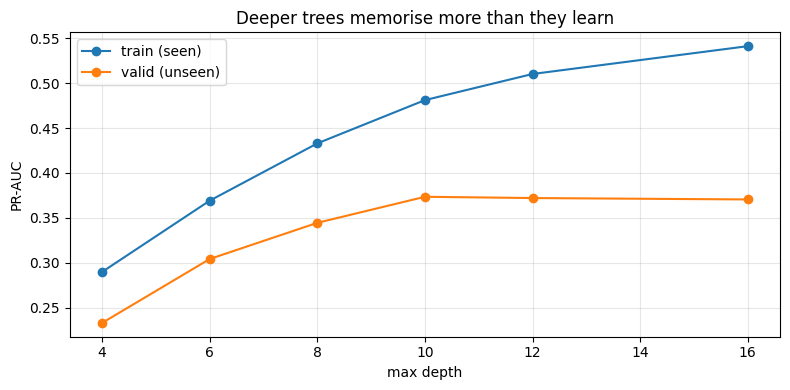

Best depth on valid: 10


In [5]:
depths = [4, 6, 8, 10, 12, 16]
rows = []
for d in depths:
    t0 = time.perf_counter()
    m = DecisionTreeClassifier(max_depth=d, min_samples_leaf=50, random_state=42).fit(X_tune, y_tune)
    s = time.perf_counter() - t0
    rows.append({"depth": d,
                 "train_pr_auc": average_precision_score(y_tune, m.predict_proba(X_tune)[:, 1]),
                 "valid_pr_auc": average_precision_score(y_valid, m.predict_proba(X_valid)[:, 1]),
                 "seconds": s})
    print(f"depth {d:>2}: valid PR-AUC {rows[-1]['valid_pr_auc']:.3f}  ({s:.0f}s)")
depth_scan = pd.DataFrame(rows)

plt.figure(figsize=(8, 4))
plt.plot(depth_scan["depth"], depth_scan["train_pr_auc"], marker="o", label="train (seen)")
plt.plot(depth_scan["depth"], depth_scan["valid_pr_auc"], marker="o", label="valid (unseen)")
plt.xlabel("max depth"); plt.ylabel("PR-AUC"); plt.title("Deeper trees memorise more than they learn")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

best_depth = int(depth_scan.loc[depth_scan["valid_pr_auc"].idxmax(), "depth"])
print(f"Best depth on valid: {best_depth}")

## 4. Cost-complexity pruning (from the course)

Grow the tree, then cut back branches that add little. `ccp_alpha` sets how harsh the cutting is:
0 = no pruning, larger = smaller tree. We try a few values on top of the best depth.

In [6]:
alphas = [0.0, 1e-5, 1e-4]
best_alpha, best_v = 0.0, -1
for a in alphas:
    m = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=50, ccp_alpha=a, random_state=42).fit(X_tune, y_tune)
    v = average_precision_score(y_valid, m.predict_proba(X_valid)[:, 1])
    print(f"alpha {a:<7}: {m.get_n_leaves():>5} leaves, valid PR-AUC {v:.3f}")
    if v > best_v:
        best_alpha, best_v = a, v

# Final model: the chosen settings, trained on the FULL training set
t0 = time.perf_counter()
pruned_tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=50, ccp_alpha=best_alpha,
                                     random_state=42).fit(X_train, y_train)
pruned_secs = time.perf_counter() - t0
print(f"\nPruned tree on all {len(X_train):,} rows: depth {best_depth}, ccp_alpha {best_alpha}, "
      f"{pruned_tree.get_n_leaves()} leaves, trained in {pruned_secs:.0f}s")
results.append(score("Decision tree (pruned)", pruned_tree, X_valid, y_valid, amount_valid, pruned_secs,
                     f"depth {best_depth}, ccp_alpha {best_alpha}, {pruned_tree.get_n_leaves()} leaves"))
show(results)

alpha 0.0    :    90 leaves, valid PR-AUC 0.374
alpha 1e-05  :    76 leaves, valid PR-AUC 0.374
alpha 0.0001 :    36 leaves, valid PR-AUC 0.353

Pruned tree on all 414,542 rows: depth 10, ccp_alpha 1e-05, 114 leaves, trained in 30s


,model,pr_auc,recall_at_1pct_fpr,cost_usd,train_seconds,ms_per_payment_single,notes
0,Decision tree (unlimited),0.1210,0.0000,492574,25.9,3.762,"no limits, 120,000-row sample"
1,Decision tree (pruned),0.3678,0.3095,420500,29.9,3.754,"depth 10, ccp_alpha 1e-05, 114 leaves"


## 5. What did the tree learn?

The top of the tree shows the questions it asks first. Feature importance shows which
columns did the most work overall.

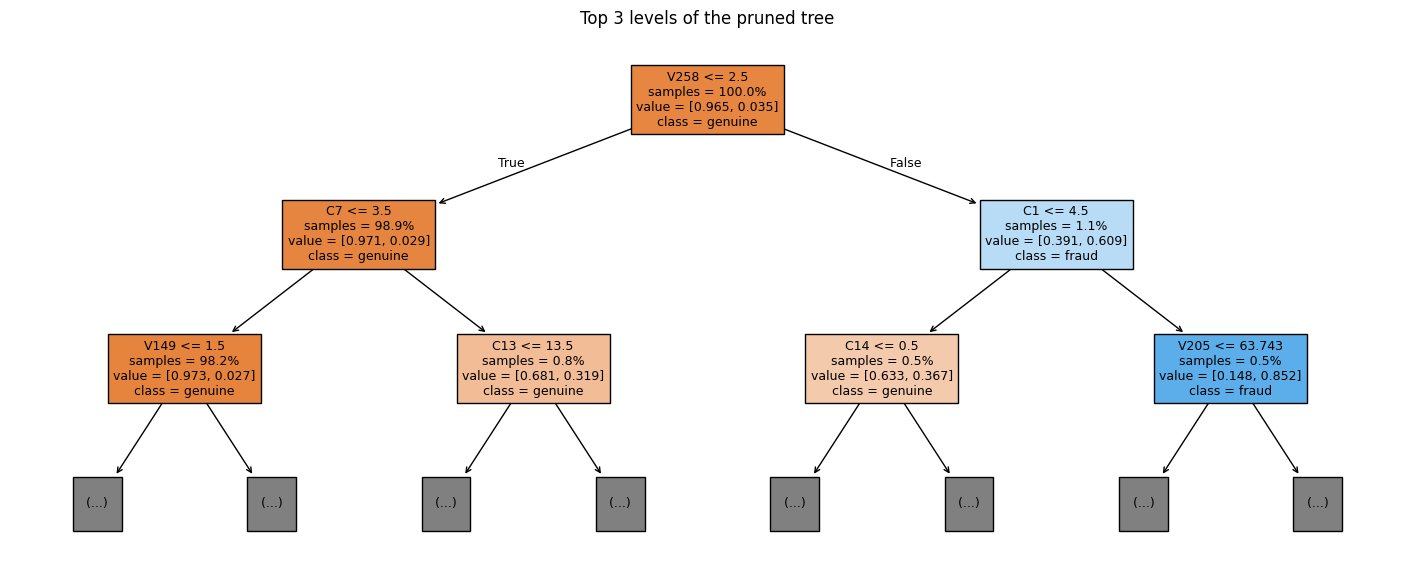

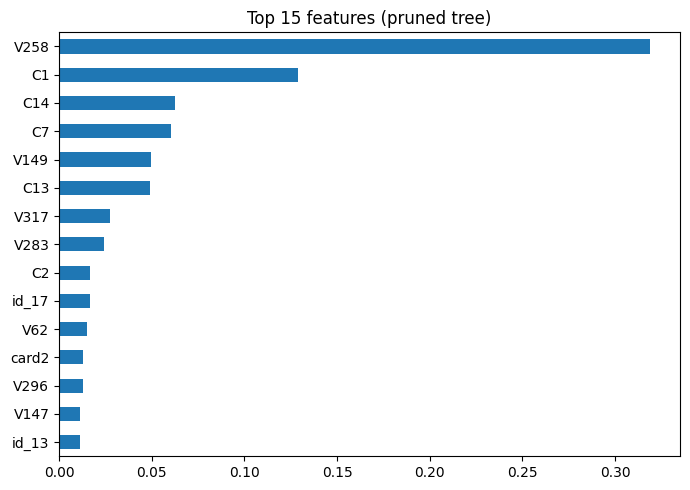

In [7]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 7))
plot_tree(pruned_tree, max_depth=2, feature_names=features, class_names=["genuine", "fraud"],
          filled=True, impurity=False, proportion=True, fontsize=9)
plt.title("Top 3 levels of the pruned tree"); plt.show()

imp = pd.Series(pruned_tree.feature_importances_, index=features).sort_values(ascending=False).head(15)
imp[::-1].plot.barh(figsize=(7, 5), title="Top 15 features (pruned tree)")
plt.tight_layout(); plt.show()

## 6. Save the results

Each contest notebook saves its rows. On Day 5 we collect them all into one table.

In [8]:
path = f"{OUT_DIR}/results_decision_tree.json"
with open(path, "w") as f:
    json.dump(results, f, indent=2)
print("saved", path)
show(results)

saved /kaggle/working/results_decision_tree.json


,model,pr_auc,recall_at_1pct_fpr,cost_usd,train_seconds,ms_per_payment_single,notes
0,Decision tree (unlimited),0.1210,0.0000,492574,25.9,3.762,"no limits, 120,000-row sample"
1,Decision tree (pruned),0.3678,0.3095,420500,29.9,3.754,"depth 10, ccp_alpha 1e-05, 114 leaves"
